# ` Intelligent E-Commerce Customer Analytics Platform `

### Purchase Prediction
    - **Objective** -  Predict whether a customer will place another order within the next 90 days.
    - **Target Variable** - Repeat Purchase

# Step 1 – Load the Featured Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings("ignore")

customer_df = pd.read_csv("../data/processed/customer_analytics_featured.csv")
customer_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,geolocation_city,geolocation_state,delivery_days,delivery_delay_days,On_Time,Purchase_Month,Purchase_Weekday,Purchase_Hour,Season,Festival_Sales_Indicator
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,...,franca,SP,8.0,-11.0,1,5,Tuesday,15,Autumn,0
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,...,sao bernardo do campo,SP,16.0,-8.0,1,1,Friday,20,Summer,0
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,...,sao paulo,SP,26.0,1.0,0,5,Saturday,16,Autumn,0
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,...,mogi das cruzes,SP,14.0,-13.0,1,3,Tuesday,16,Autumn,0
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,...,campinas,SP,11.0,-6.0,1,7,Sunday,9,Winter,0


# Step 2 – Create the Target Variable

In [2]:
# Convert purchase Date
customer_df["order_purchase_timestamp"] = pd.to_datetime(
    customer_df["order_purchase_timestamp"]
)

# Sort Customer Purchase
customer_df = customer_df.sort_values(
    ["customer_unique_id", "order_purchase_timestamp"]
)

# Find Next Purchase Date
customer_df["Next_Purchase_Date"] = (
    customer_df.groupby("customer_unique_id")["order_purchase_timestamp"]
               .shift(-1)
)

# Calculate Days Until Next Purchase
customer_df["Days_To_Next_Purchase"] = (
    customer_df["Next_Purchase_Date"]
    - customer_df["order_purchase_timestamp"]
).dt.days

# Create Target Variable
customer_df["Repeat_Purchase"] = np.where(
    customer_df["Days_To_Next_Purchase"] <= 90,
    1,
    0
)

In [3]:
# Handle Last Purchase
    # Customers with no future purchase have NaN for Days_To_Next_Purchase.

customer_df["Repeat_Purchase"] = (
    customer_df["Repeat_Purchase"]
    .fillna(0)
    .astype(int)
)

# Target Distribution
customer_df["Repeat_Purchase"].value_counts()

Repeat_Purchase
0    97112
1    22031
Name: count, dtype: int64

In [4]:
# Percentage Distribution 
(
customer_df["Repeat_Purchase"]
.value_counts(normalize=True)
*100
).round(2)

Repeat_Purchase
0    81.51
1    18.49
Name: proportion, dtype: float64

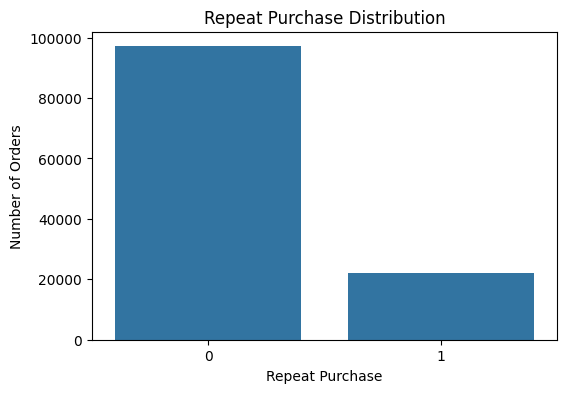

In [5]:
# Visualization

plt.figure(figsize=(6,4))
sns.countplot(data=customer_df, x="Repeat_Purchase")
plt.title("Repeat Purchase Distribution")
plt.xlabel("Repeat Purchase")
plt.ylabel("Number of Orders")
plt.show()

## Interpretation:
### Most purchases are not followed by another purchase within 90 days.
### The dataset is likely to be imbalanced, which is expected in customer retention problems.

# Step 3 – Prepare the Modeling Dataset

In [6]:
# Check Duplicate Orders

model_df = customer_df.drop_duplicates(subset="order_id").copy()
print("Dataset Shape:", model_df.shape)
print("Duplicate Orders:", model_df["order_id"].duplicated().sum())

Dataset Shape: (99441, 56)
Duplicate Orders: 0


In [7]:
# Remove Leakage Columns

drop_columns = [

    # IDs
    "customer_id",
    "customer_unique_id",
    "order_id",
    "review_id",
    "product_id",
    "seller_id",

    # Free text
    "review_comment_title",
    "review_comment_message",

    # Raw timestamps
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_delivered_carrier_date",
    "order_estimated_delivery_date",
    "shipping_limit_date",
    "review_creation_date",
    "review_answer_timestamp",

    # Leakage
    "Next_Purchase_Date",
    "Days_To_Next_Purchase",
    "Repeat_Purchase"
]

X = customer_df.drop(columns=drop_columns)
y = customer_df["Repeat_Purchase"]
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)
X.info()

Feature Shape: (119143, 37)
Target Shape: (119143,)
<class 'pandas.DataFrame'>
Index: 119143 entries, 76714 to 100279
Data columns (total 37 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   customer_zip_code_prefix       119143 non-null  int64  
 1   customer_city                  119143 non-null  str    
 2   customer_state                 119143 non-null  str    
 3   order_status                   119143 non-null  str    
 4   order_item_id                  118310 non-null  float64
 5   price                          118310 non-null  float64
 6   freight_value                  118310 non-null  float64
 7   product_category_name          116601 non-null  str    
 8   product_name_lenght            119143 non-null  float64
 9   product_description_lenght     119143 non-null  float64
 10  product_photos_qty             119143 non-null  float64
 11  product_weight_g               119143 non-null  flo

In [8]:
# Identify Numerical Features
numeric_features = X.select_dtypes(include="number").columns.tolist()
print("Numeric Features :")
print(numeric_features)

# Identify Categorical Features
categorical_features = X.select_dtypes(include="object").columns.tolist()
print("\nCategorical Fatures :")
print(categorical_features)

Numeric Features :
['customer_zip_code_prefix', 'order_item_id', 'price', 'freight_value', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'seller_zip_code_prefix', 'payment_sequential', 'payment_installments', 'payment_value', 'review_score', 'geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'delivery_days', 'delivery_delay_days', 'On_Time', 'Purchase_Month', 'Purchase_Hour', 'Festival_Sales_Indicator']

Categorical Fatures :
['customer_city', 'customer_state', 'order_status', 'product_category_name', 'product_category_name_english', 'seller_city', 'seller_state', 'payment_type', 'geolocation_city', 'geolocation_state', 'Purchase_Weekday', 'Season']


# Step 4 – Feature Encoding & Data Preprocessing

In [ ]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("\nCategorical Columns:")
print(categorical_features)

# ====== Train-Test Split ========

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("\nTraining Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)


Numerical Features: 25
Categorical Features: 12

Categorical Columns:
['customer_city', 'customer_state', 'order_status', 'product_category_name', 'product_category_name_english', 'seller_city', 'seller_state', 'payment_type', 'geolocation_city', 'geolocation_state', 'Purchase_Weekday', 'Season']

Training Shape : (95314, 37)
Testing Shape  : (23829, 37)


Processed Training Shape: (95314, 8735)
Processed Testing Shape : (23829, 8735)
Training Target Distribution:
Repeat_Purchase
0    0.815085
1    0.184915
Name: proportion, dtype: float64

Testing Target Distribution:
Repeat_Purchase
0    0.815099
1    0.184901
Name: proportion, dtype: float64


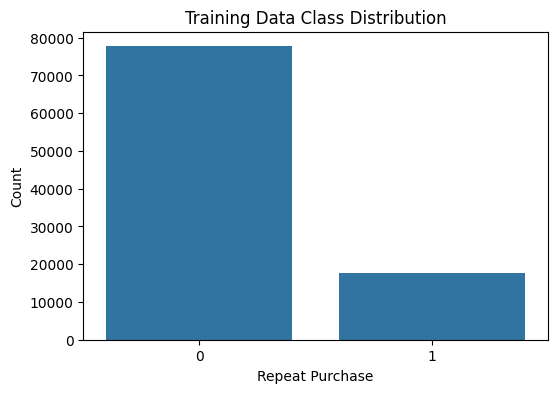

In [10]:
# Create Preprocessing Pipelines

numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_transformer = Pipeline([ ("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),  ("cat", categorical_transformer, categorical_features)])

# Transform the data

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape :", X_test_processed.shape)

# Check class distribution 

print("Training Target Distribution:")
print(y_train.value_counts(normalize=True))
print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

# Visualization

plt.figure(figsize=(6,4))
sns.countplot(x=y_train)
plt.title("Training Data Class Distribution")
plt.xlabel("Repeat Purchase")
plt.ylabel("Count")
plt.show()


# Step 5 – Handling Class Imbalance

In [11]:
!pip3 install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE")
print(y_train.value_counts())
print("\nPercentage")
print((y_train.value_counts(normalize=True)*100).round(2))

Before SMOTE
Repeat_Purchase
0    77689
1    17625
Name: count, dtype: int64

Percentage
Repeat_Purchase
0    81.51
1    18.49
Name: proportion, dtype: float64


# Apply SMOTE


In [13]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)
print("After SMOTE")
print(y_train_balanced.value_counts())
print("Original Training Shape :", X_train_processed.shape)
print("Balanced Training Shape :", X_train_balanced.shape)

After SMOTE
Repeat_Purchase
0    77689
1    77689
Name: count, dtype: int64
Original Training Shape : (95314, 8735)
Balanced Training Shape : (155378, 8735)


# Step 6 – Model 1: Logistic Regression

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,classification_report)


log_model = LogisticRegression(random_state=42, max_iter=1000)
log_model.fit(X_train_balanced, y_train_balanced)
y_pred = log_model.predict(X_test_processed)
y_prob = log_model.predict_proba(X_test_processed)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))
print("ROC-AUC  :", round(roc_auc,4))

print(classification_report(y_test, y_pred))

Accuracy : 0.8161
Precision: 0.502
Recall   : 0.6931
F1 Score : 0.5823
ROC-AUC  : 0.8169
              precision    recall  f1-score   support

           0       0.92      0.84      0.88     19423
           1       0.50      0.69      0.58      4406

    accuracy                           0.82     23829
   macro avg       0.71      0.77      0.73     23829
weighted avg       0.85      0.82      0.83     23829



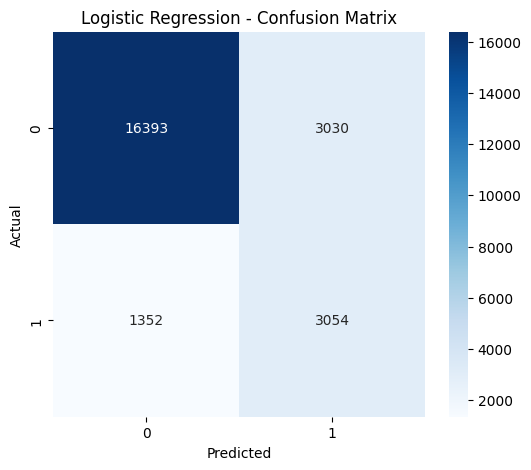

In [15]:
# Visualization

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True,  fmt="d", cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [16]:
# Saving the  Results

model_results = []
model_results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
})

# Model 2 – Decision Tree Classifier

In [17]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10,         
    min_samples_split=20,
    min_samples_leaf=10
)

dt_model.fit(X_train_balanced, y_train_balanced)
y_pred_dt = dt_model.predict(X_test_processed)
y_prob_dt = dt_model.predict_proba(X_test_processed)[:,1]
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Accuracy :", round(accuracy_dt,4))
print("Precision:", round(precision_dt,4))
print("Recall   :", round(recall_dt,4))
print("F1 Score :", round(f1_dt,4))
print("ROC-AUC  :", round(roc_auc_dt,4))

print(classification_report(y_test, y_pred_dt))

Accuracy : 0.9241
Precision: 0.792
Recall   : 0.7994
F1 Score : 0.7957
ROC-AUC  : 0.9047
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     19423
           1       0.79      0.80      0.80      4406

    accuracy                           0.92     23829
   macro avg       0.87      0.88      0.87     23829
weighted avg       0.92      0.92      0.92     23829



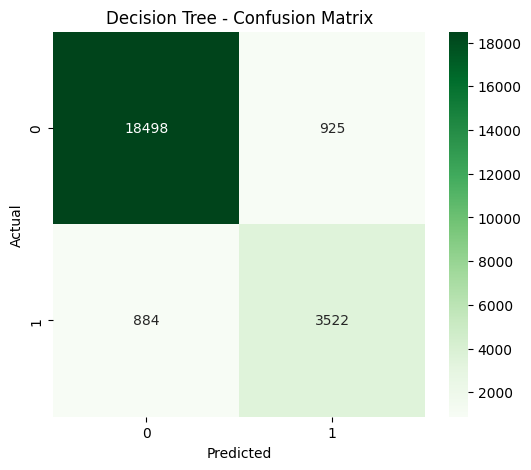

In [18]:
# Visualization

cm = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True, fmt="d",cmap="Greens")
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
# Saving the Results
model_results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1 Score": f1_dt,
    "ROC-AUC": roc_auc_dt
})

# Model 3 – Random Forest Classifier

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_balanced, y_train_balanced)

y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))

print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))

Accuracy : 0.8102
Precision: 0.486
Recall   : 0.4612
F1 Score : 0.4733
ROC-AUC  : 0.764

Classification Report
              precision    recall  f1-score   support

           0       0.88      0.89      0.88     19423
           1       0.49      0.46      0.47      4406

    accuracy                           0.81     23829
   macro avg       0.68      0.68      0.68     23829
weighted avg       0.81      0.81      0.81     23829



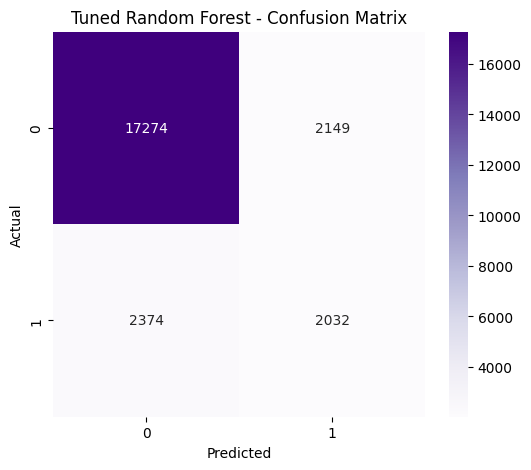

In [21]:
# Visualization 
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True, fmt="d",cmap="Purples")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [24]:
# Saving the Results

model_results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1 Score": f1_rf,
    "ROC-AUC": roc_auc_rf
})

# Model 4 – Gradient Boosting Classifier

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_balanced, y_train_balanced)
y_pred_gb = gb_model.predict(X_test_processed)
y_prob_gb = gb_model.predict_proba(X_test_processed)[:,1]

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
roc_auc_gb = roc_auc_score(y_test, y_prob_gb)

print("Accuracy :", round(accuracy_gb,4))
print("Precision:", round(precision_gb,4))
print("Recall   :", round(recall_gb,4))
print("F1 Score :", round(f1_gb,4))
print("ROC-AUC  :", round(roc_auc_gb,4))

print(classification_report(y_test, y_pred_gb))

Accuracy : 0.9058
Precision: 0.7663
Recall   : 0.7061
F1 Score : 0.7349
ROC-AUC  : 0.9033
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     19423
           1       0.77      0.71      0.73      4406

    accuracy                           0.91     23829
   macro avg       0.85      0.83      0.84     23829
weighted avg       0.90      0.91      0.90     23829



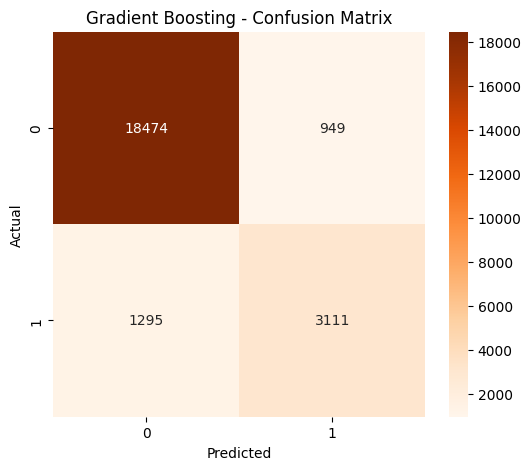

In [26]:
# Visualization

cm = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True, fmt="d", cmap="Oranges")
plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [27]:
# Saving the Result

model_results.append({
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_gb,
    "Precision": precision_gb,
    "Recall": recall_gb,
    "F1 Score": f1_gb,
    "ROC-AUC": roc_auc_gb
})

# Model 5 – XGBoost Classifier

In [29]:
!pip3 install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.5 MB/s eta 0:00:32
    --------------------------------------- 0.8/48.9 MB 1.3 MB/s eta 0:00:36
    --------------------------------------- 1.0/48.9 MB 1.3 MB/s eta 0:00:37
   - -------------------------------------- 1.3/48.9 MB 1.4 MB/s eta 0:00:35
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:34
   - -------------------------------------- 1.8/48.9 MB 1.4 MB/s eta 0:00:34
   - -------------------------------------- 2.1/48.9 MB 1.4 MB/s eta 0:00:35
   - -------------------------------------- 2.4/48.9 MB 1.3 MB/s eta 0:00:36
   -- ------------------------------------- 2.6/48.9 MB 1.3 MB/s eta 0:00:37
   -- -------------


[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_model.fit(X_train_balanced,  y_train_balanced)
y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("Accuracy :", round(accuracy_xgb,4))
print("Precision:", round(precision_xgb,4))
print("Recall   :", round(recall_xgb,4))
print("F1 Score :", round(f1_xgb,4))
print("ROC-AUC  :", round(roc_auc_xgb,4))

print("\nClassification Report")
print(classification_report(y_test, y_pred_xgb))

Accuracy : 0.9189
Precision: 0.8255
Recall   : 0.712
F1 Score : 0.7646
ROC-AUC  : 0.9236

Classification Report
              precision    recall  f1-score   support

           0       0.94      0.97      0.95     19423
           1       0.83      0.71      0.76      4406

    accuracy                           0.92     23829
   macro avg       0.88      0.84      0.86     23829
weighted avg       0.92      0.92      0.92     23829



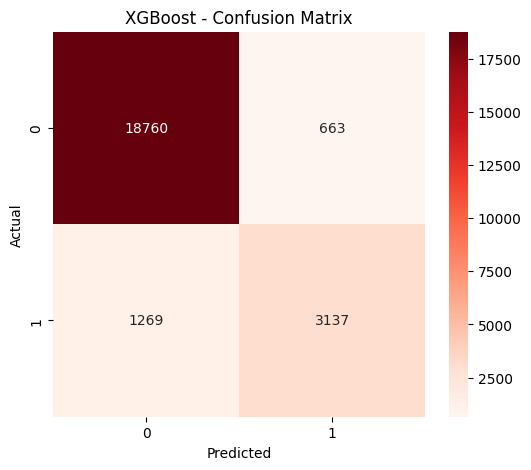

In [31]:
# Visualization

cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True, fmt="d", cmap="Reds")
plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [32]:
# Saving the results

model_results.append({
    "Model": "XGBoost",
    "Accuracy": accuracy_xgb,
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1 Score": f1_xgb,
    "ROC-AUC": roc_auc_xgb
})

# Model 6: LightGBM Classifier

In [33]:
!pip3 install lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 2.8 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 3.1 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 3.2 MB/s  0:00:00



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    num_leaves=31,
    random_state=42
)

lgbm_model.fit(X_train_balanced,   y_train_balanced)
y_pred_lgb = lgbm_model.predict(X_test_processed)
y_prob_lgb = lgbm_model.predict_proba(X_test_processed)[:,1]

accuracy_lgb = accuracy_score(y_test, y_pred_lgb)
precision_lgb = precision_score(y_test, y_pred_lgb)
recall_lgb = recall_score(y_test, y_pred_lgb)
f1_lgb = f1_score(y_test, y_pred_lgb)
roc_auc_lgb = roc_auc_score(y_test, y_prob_lgb)

print("Accuracy :", round(accuracy_lgb,4))
print("Precision:", round(precision_lgb,4))
print("Recall   :", round(recall_lgb,4))
print("F1 Score :", round(f1_lgb,4))
print("ROC-AUC  :", round(roc_auc_lgb,4))

print(classification_report(y_test, y_pred_lgb))

[LightGBM] [Info] Number of positive: 77689, number of negative: 77689
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.779025 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 99344
[LightGBM] [Info] Number of data points in the train set: 155378, number of used features: 2573
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Accuracy : 0.9268
Precision: 0.8281
Recall   : 0.7621
F1 Score : 0.7938
ROC-AUC  : 0.9322
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     19423
           1       0.83      0.76      0.79      4406

    accuracy                           0.93     23829
   macro avg       0.89      0.86      0.87     23829
weighted avg       0.93      0.93      0.93     23829



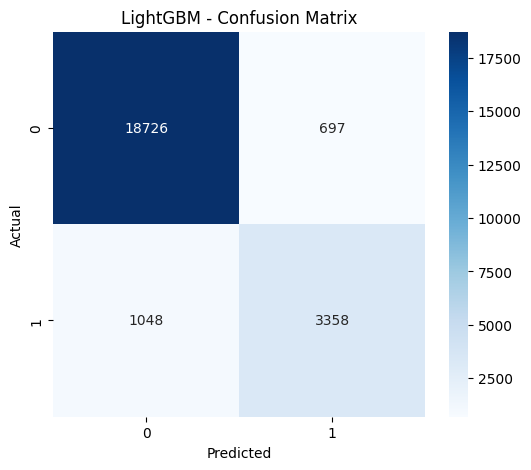

In [35]:
# Visualization

cm = confusion_matrix(y_test, y_pred_lgb)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True,  fmt="d", cmap="Blues")
plt.title("LightGBM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [36]:
model_results.append({
    "Model": "LightGBM",
    "Accuracy": accuracy_lgb,
    "Precision": precision_lgb,
    "Recall": recall_lgb,
    "F1 Score": f1_lgb,
    "ROC-AUC": roc_auc_lgb
})

In [37]:

comparison_df = pd.DataFrame(model_results)
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.816106,0.501972,0.693146,0.582269,0.816942
1,Decision Tree,0.924084,0.791995,0.799365,0.795662,0.904656
2,Random Forest,0.810189,0.486008,0.461189,0.473274,0.764032
3,Random Forest,0.810189,0.486008,0.461189,0.473274,0.764032
4,Gradient Boosting,0.905829,0.766256,0.706083,0.734940,0.903315
5,XGBoost,0.918922,0.825526,0.711984,0.764563,0.923632
6,LightGBM,0.926770,0.828113,0.762143,0.793760,0.932156


# Interpretation

## LightGBM — Best Overall
    - Highest Accuracy (92.68%)
    - Highest Precision (82.81%)
    - Highest ROC-AUC (93.22%)
    - Excellent F1-Score (79.38%)

## Business Insight
    - LightGBM is the best choice when marketing budgets are limited because it minimizes false positives while maintaining strong predictive performance.

# Step 7 - Save the best model

In [ ]:
import joblib

model_path = r"C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\artifacts\lightgbm_repeat_purchase_model.pkl"
joblib.dump(lgbm_model, model_path)
print("Model Saved Successfully!")

Model Saved Successfully!


In [44]:
loaded_model = joblib.load(model_path)
type(loaded_model)

lightgbm.sklearn.LGBMClassifier

In [45]:
preprocessor_path = r"C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\artifacts\preprocessor.pkl"
joblib.dump(preprocessor, preprocessor_path)
print("Preprocessor Saved Successfully!")

Preprocessor Saved Successfully!


# Step 8 - Build the Prediction Pipeline

In [49]:
# Load Saved Objects
import joblib
model = joblib.load("../artifacts/lightgbm_repeat_purchase_model.pkl")
preprocessor = joblib.load("../artifacts/preprocessor.pkl")

# Create Sample Customer
sample_customer = X_test.iloc[[0]]
sample_customer.head()  

# Apply Preprocessor
sample_processed = preprocessor.transform(sample_customer)
print(sample_processed.shape)

# Predict
prediction = model.predict(sample_processed)
probability = model.predict_proba(sample_processed)
print("Prediction:", prediction[0])
print("Probability:", probability[0])

if prediction[0] == 1:
    print("Customer is likely to make a Repeat Purchase.")
else:
    print("Customer is NOT likely to make a Repeat Purchase.")


(1, 8735)
Prediction: 0
Probability: [0.94491112 0.05508888]
Customer is NOT likely to make a Repeat Purchase.


In [50]:
def predict_repeat_purchase(customer_data):
    processed = preprocessor.transform(customer_data)
    prediction = model.predict(processed)[0]
    probability = model.predict_proba(processed)[0][1]
    return prediction, probability

prediction, probability = predict_repeat_purchase(sample_customer)
print("Prediction :", prediction)
print("Probability:", round(probability, 4))

Prediction : 0
Probability: 0.0551


# Step 9: Feature Importance Analysis (Best Model – LightGBM)

In [ ]:
# =====  Feature Importance  ==========

feature_names = preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lgbm_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
importance_df.to_csv("../artifacts/feature_importance.csv", index=False)
importance_df.head(20)

,Feature,Importance
14,num__payment_value,648
2,num__price,495
1,num__order_item_id,367
12,num__payment_sequential,159
3,num__freight_value,148
13,num__payment_installments,69
15,num__review_score,69
4720,cat__payment_type_voucher,65
6,num__product_photos_qty,48
20,num__delivery_delay_days,39


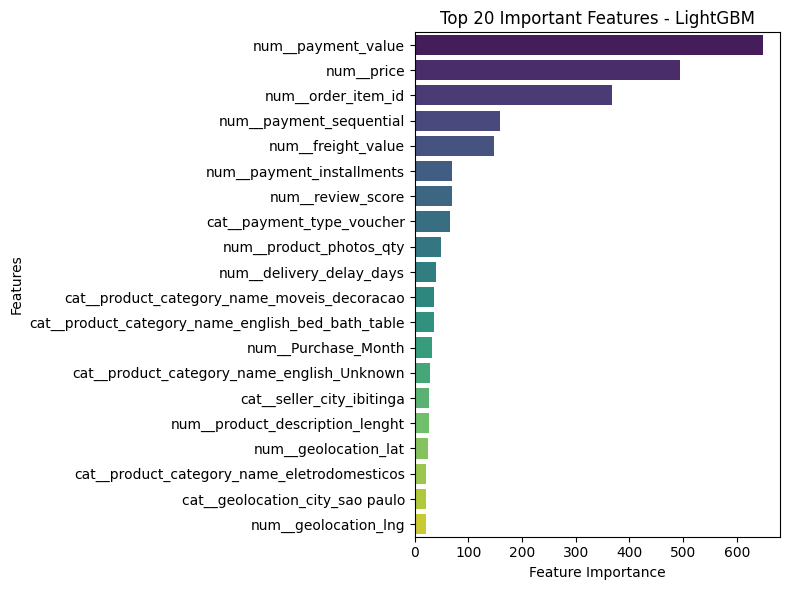

In [52]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=importance_df.head(20),
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Top 20 Important Features - LightGBM")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()